<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/07_antes_e_depois.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/07_antes_e_depois.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 07 — O dinheiro a mais virou melhoria? Antes e depois das usinas

**Pergunta:** no notebook 06 vimos que as cidades com usinas eólicas ou de petróleo e gás recebem muito mais repasse
que cidades parecidas, e que esse dinheiro vai para a prefeitura. **A vida da população dessas cidades melhorou
mais?**

**Termos usados:**
- **Cidades com usinas:** os 7 municípios que mais recebem repasse por habitante (os "outliers" dos notebooks
  03 e 04): Guamaré, São Bento do Norte, Pedra Grande, Parazinho, Galinhos, Bodó e Serra do Mel.
- **Cidade parecida (sem usina):** para cada cidade com usina, o município que **em 2010** era mais parecido com ela
  (tamanho, pobreza e região), mas cujo repasse quase não cresceu e que não tem indústria forte.
- **Antes** = por volta de 2010, quando a maioria das usinas ainda não existia. **Depois** = por volta de 2022.

**Ideia do teste:** se o dinheiro a mais virou serviço para a população, as cidades com usinas deveriam ter
**melhorado mais** que as cidades parecidas entre o antes e o depois.

**O que medimos:**

| Área | Indicador | Antes | Depois | Fonte |
|---|---|---|---|---|
| Renda | renda média por pessoa; % de pessoas com até ½ salário mínimo | 2010 | 2022 | Censo (IBGE) |
| Saneamento | % de domicílios com esgoto adequado, lixo coletado e água da rede | 2010 | 2022 | Censo (IBGE) |
| Educação | nota do IDEB das escolas **municipais** (1º ao 5º ano) | 2005 a 2023 | | INEP |
| Saúde | mortalidade infantil (mortes de bebês com menos de 1 ano a cada mil nascidos) | 2008 a 2012 | 2019 a 2023 | DATASUS |

## 1. Bibliotecas e estilo

In [1]:
import gzip
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
CINZA, CINZA_CLARO = '#a3a29b', '#d6d5d0'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, **kwargs):
    """Lê do GitHub do projeto; se não conseguir, lê a cópia local (mesmo caminho)."""
    try:
        return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
    except Exception as erro:
        if os.path.exists(caminho):
            return pd.read_csv(caminho, **kwargs)
        if '404' in str(erro):
            raise FileNotFoundError(
                f'O arquivo "{caminho}" não está no GitHub do projeto. '
                f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
                'e rode a célula de novo.') from None
        raise ConnectionError(
            f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
            'No Kaggle, ligue a opção "Internet" no painel lateral (Settings) e rode de novo. '
            f'Erro original: {erro}') from None

os.makedirs('graficos', exist_ok=True)  # pasta onde os gráficos são salvos (no Colab ela não existe)

CIDADES_USINAS = ['Guamaré', 'São Bento do Norte', 'Pedra Grande', 'Parazinho', 'Galinhos', 'Bodó', 'Serra do Mel']

## 2. Os dados

### 2.1 Repasse por habitante, antes e depois
Para não depender de um ano isolado, usamos a **média de 3 anos**: antes = 2008 a 2010; depois = 2020 a 2022.
Valores em R$ de 2025 (corrigidos pela inflação), da série longa (notebooks 05_a e 05_b).

In [2]:
repasses = ler_csv('saida/repasses_2004_2025.csv')
indicadores = ler_csv('saida/indicadores_2004_2025.csv')
base23 = ler_csv('saida/base_municipios_2020_2023.csv').drop_duplicates('cod_ibge').set_index('cod_ibge')

total = repasses.groupby(['cod_ibge', 'ano'])['valor'].sum().rename('repasse').reset_index()
painel = total.merge(indicadores[['cod_ibge', 'ano', 'municipio', 'populacao', 'fator_ipca_2025']], on=['cod_ibge', 'ano'])
painel['rep_pc'] = painel['repasse'] * painel['fator_ipca_2025'] / painel['populacao']

d = pd.DataFrame({
    'municipio': painel.drop_duplicates('cod_ibge').set_index('cod_ibge')['municipio'],
    'rep_antes': painel[painel['ano'].between(2008, 2010)].groupby('cod_ibge')['rep_pc'].mean(),
    'rep_depois': painel[painel['ano'].between(2020, 2022)].groupby('cod_ibge')['rep_pc'].mean(),
    'pop10': indicadores[indicadores['ano'] == 2010].set_index('cod_ibge')['populacao'],
}).join(base23[['mesorregiao']])
d.index = d.index.astype(int)
d['vezes_rep'] = d['rep_depois'] / d['rep_antes']
d['com_usina'] = d['municipio'].isin(CIDADES_USINAS)
print(len(d), 'municípios')

167 municípios


### 2.2 Censo 2010 e 2022 (renda e saneamento)
Para o notebook rodar rápido lemos a cópia `dados/ibge/censo2010_2022_indicadores_rn.csv`, montada com estas tabelas
do IBGE (SIDRA):
- **2010:** 3578 (renda e classes de renda por pessoa), 3217 (água da rede e lixo coletado), 3218 (esgoto: rede
  geral, pluvial ou fossa séptica);
- **2022:** 10295 e 10296 (renda; cópia em `censo2022_renda_rn.csv`), 6803 (ligação à rede de água), 6892 (lixo
  coletado), 6805 (esgoto: rede geral, pluvial ou fossa séptica).

In [3]:
censos = ler_csv('dados/ibge/censo2010_2022_indicadores_rn.csv').set_index('cod_ibge')
censo22 = ler_csv('dados/ibge/censo2022_renda_rn.csv').set_index('cod_ibge')
d = d.join(censos).join(censo22[['pct_ate_meio_sm_censo', 'renda_media_pc']].rename(
    columns={'pct_ate_meio_sm_censo': 'pobre22', 'renda_media_pc': 'renda22'}))

fator = indicadores[indicadores['ano'].isin([2010, 2022])].drop_duplicates('ano').set_index('ano')['fator_ipca_2025']
inflacao_2010_2022 = fator[2010] / fator[2022]
print(f'Inflação (IPCA) de 2010 a 2022: os preços multiplicaram por {virgula(inflacao_2010_2022, 2)}')
d['renda10_preco22'] = d['renda10'] * inflacao_2010_2022       # renda de 2010 em R$ de 2022, para comparar

d['renda_cresc'] = (d['renda22'] / d['renda10_preco22'] - 1) * 100   # crescimento real, em %
d['queda_pobreza'] = d['pobre10'] - d['pobre22']                     # pontos percentuais
d['mais_esgoto'] = d['esg22'] - d['esg10']
d['mais_lixo'] = d['lixo22'] - d['lixo10']
d['mais_agua'] = d['agua22'] - d['agua10']

Inflação (IPCA) de 2010 a 2022: os preços multiplicaram por 2,04


### 2.3 IDEB das escolas municipais (INEP)
O IDEB (de 0 a 10) junta a nota da Prova Brasil/SAEB e a aprovação. Usamos só a **rede municipal** (escolas da
prefeitura) do **1º ao 5º ano**, que é onde a prefeitura mais atua. Para a comparação de antes e depois: antes =
média de 2009 e 2011; depois = média de 2019 e 2023 (2021 fica fora por causa da pandemia).

**Fonte:** planilhas "divulgação municípios 2023" do INEP. Cópia em `dados/inep/ideb_rede_municipal_rn.csv`.

In [4]:
ideb = ler_csv('dados/inep/ideb_rede_municipal_rn.csv').set_index('cod_ibge')
d = d.join(ideb)
for etapa in ['ai', 'af']:
    d[f'{etapa}_antes'] = d[[f'{etapa}_2009', f'{etapa}_2011']].mean(axis=1)
    d[f'{etapa}_depois'] = d[[f'{etapa}_2019', f'{etapa}_2023']].mean(axis=1)
    d[f'mais_ideb_{etapa}'] = d[f'{etapa}_depois'] - d[f'{etapa}_antes']
print('Municípios com IDEB antes e depois — 1º ao 5º ano:', d['mais_ideb_ai'].notna().sum(),
      '| 6º ao 9º ano:', d['mais_ideb_af'].notna().sum())

Municípios com IDEB antes e depois — 1º ao 5º ano: 162 | 6º ao 9º ano: 145


### 2.4 Mortalidade infantil (DATASUS, pela API do IBGE Cidades)
Nas cidades pequenas nascem poucas crianças por ano (Bodó: cerca de 45), então uma única morte muda muito a taxa.
Por isso somamos **5 anos**: antes = 2008 a 2012; depois = 2019 a 2023.

In [5]:
COD6 = '|'.join(str(int(c) // 10) for c in d.index)
try:
    # urllib em vez de requests: a API do IBGE não aceita o "|" codificado como %7C
    url = f'https://servicodados.ibge.gov.br/api/v1/pesquisas/39/periodos/all/indicadores/78159|78160/resultados/{COD6}'
    with urllib.request.urlopen(url, timeout=120) as resposta:
        conteudo = resposta.read()
    if conteudo[:2] == b'\x1f\x8b':                    # a API às vezes manda a resposta compactada (gzip)
        conteudo = gzip.decompress(conteudo)
    dados_api = json.loads(conteudo.decode('utf-8'))
    nomes = {78159: 'nascidos_vivos', 78160: 'obitos_menor_1_ano'}
    saude = pd.DataFrame([{'indicador': nomes[b['id']], 'cod_ibge6': int(x['localidade']), 'ano': int(a), 'valor': v}
                          for b in dados_api for x in b['res'] for a, v in x['res'].items()])
except Exception as erro:
    print('API do IBGE não respondeu, usando a cópia:', type(erro).__name__)
    saude = ler_csv('dados/saude/mortalidade_infantil_rn.csv')
saude['valor'] = pd.to_numeric(saude['valor'].astype(str).replace('-', '0'), errors='coerce')   # '-' = nenhum caso
saude = saude[saude['indicador'] != 'taxa'].pivot_table(index=['cod_ibge6', 'ano'], columns='indicador', values='valor').reset_index()

def mortalidade(inicio, fim):
    t = saude[saude['ano'].between(inicio, fim)].groupby('cod_ibge6')[['obitos_menor_1_ano', 'nascidos_vivos']].sum()
    return t['obitos_menor_1_ano'] / t['nascidos_vivos'] * 1000

d['cod_ibge6'] = d.index.astype(int) // 10
d = d.join(pd.DataFrame({'mi_antes': mortalidade(2008, 2012), 'mi_depois': mortalidade(2019, 2023)}), on='cod_ibge6')
d['queda_mort_infantil'] = d['mi_antes'] - d['mi_depois']

API do IBGE não respondeu, usando a cópia: URLError


## 3. As cidades parecidas (sem usina)

Para cada cidade com usina escolhemos o município que **em 2010** era mais parecido com ela em:
- **população** (em escala log: 3 mil e 3,5 mil são parecidos);
- **pobreza** (% de pessoas com até ½ salário mínimo, Censo 2010);
- **região** (se for de outra mesorregião, conta como meio desvio-padrão a mais de distância).

Só entram como candidatas cidades cujo repasse **cresceu menos de 2 vezes** e que **não têm indústria forte**
(indústria com menos de 20% do valor adicionado em 2021; IBGE, cópia em `dados/ibge/vab_setor_rn.csv`).

In [6]:
vab = ler_csv('dados/ibge/vab_setor_rn.csv', dtype={'variavel': str})
vab21 = vab[vab['ano'] == 2021].pivot_table(index='cod_ibge', columns='variavel', values='valor_mil')
d['pct_industria'] = vab21['517'] / vab21['498'] * 100

d['log_pop'] = np.log(d['pop10'])
dp_pop, dp_pobre = d['log_pop'].std(), d['pobre10'].std()
candidatas = d[~d['com_usina'] & (d['vezes_rep'] < 2) & (d['pct_industria'] < 20)]

def parecida_2010(nome):
    a = d[d['municipio'] == nome].iloc[0]
    dist = (((candidatas['log_pop'] - a['log_pop']) / dp_pop).abs()
            + ((candidatas['pobre10'] - a['pobre10']) / dp_pobre).abs()
            + (candidatas['mesorregiao'] != a['mesorregiao']) * 0.5)
    return candidatas.loc[dist.idxmin(), 'municipio']

PARES = pd.DataFrame({'com_usina': CIDADES_USINAS, 'parecida': [parecida_2010(c) for c in CIDADES_USINAS]})
PARECIDAS = list(dict.fromkeys(PARES['parecida']))
info = d.set_index('municipio')

tabela = pd.DataFrame({
    'cidade com usina': PARES['com_usina'],
    'cidade parecida (sem usina)': PARES['parecida'],
    'habitantes 2010 (com usina)': [info.loc[c, 'pop10'] for c in PARES['com_usina']],
    'habitantes 2010 (parecida)': [info.loc[c, 'pop10'] for c in PARES['parecida']],
    '% pobres 2010 (com usina)': [info.loc[c, 'pobre10'] for c in PARES['com_usina']],
    '% pobres 2010 (parecida)': [info.loc[c, 'pobre10'] for c in PARES['parecida']],
})
tabela

,cidade com usina,cidade parecida (sem usina),habitantes 2010 (com usina),habitantes 2010 (parecida),% pobres 2010 (com usina),% pobres 2010 (parecida)
0,Guamaré,Acari,12404,11035,53.5,49.9
1,São Bento do Norte,Água Nova,2975,2980,76.0,75.0
2,Pedra Grande,Senador Georgino Avelino,3521,3924,72.2,72.3
3,Parazinho,Sítio Novo,4845,5020,70.8,72.1
4,Galinhos,Taboleiro Grande,2159,2317,69.3,67.4
5,Bodó,Taboleiro Grande,2425,2317,66.1,67.4
6,Serra do Mel,Umarizal,10287,10659,67.2,62.7


**Observação:** Taboleiro Grande é a cidade parecida de Galinhos e de Bodó ao mesmo tempo (as duas eram muito
semelhantes a ela em 2010). Por isso são 6 cidades parecidas para 7 cidades com usinas.

## 4. Quanto o repasse cresceu

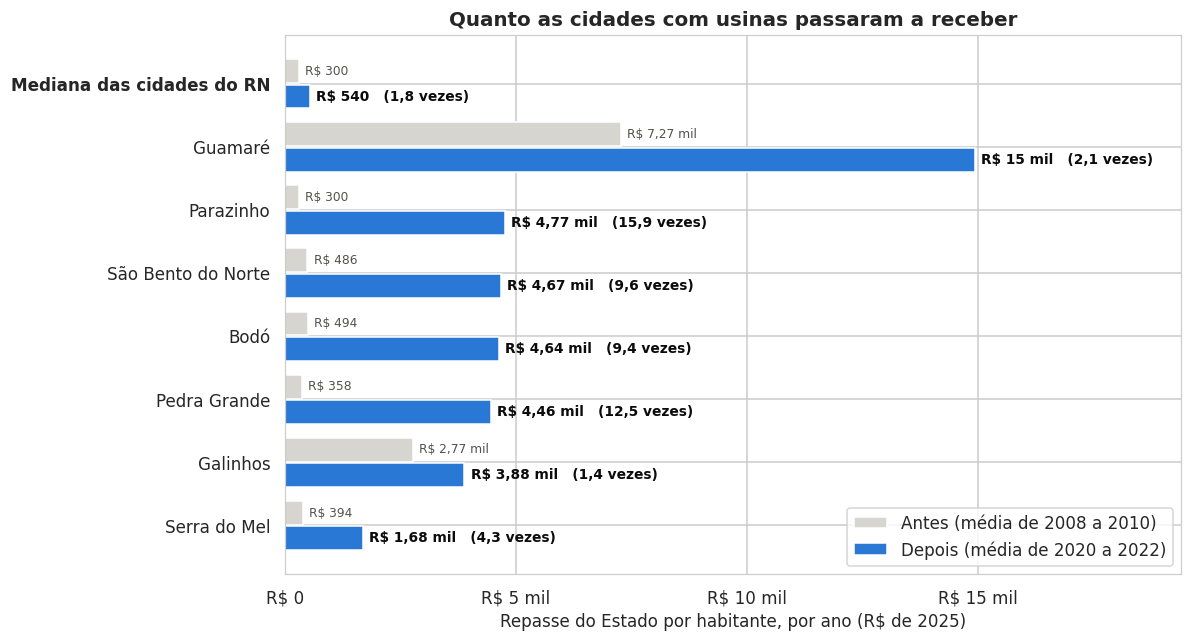

In [7]:
GRUPOS = {
    f'Cidades com usinas ({len(CIDADES_USINAS)})': CIDADES_USINAS,
    f'Cidades parecidas, sem usina ({len(PARECIDAS)})': PARECIDAS,
    f'Todas as cidades do RN ({len(d)})': list(d['municipio']),
}
CORES_GRUPO = [AZUL, CINZA, VERDE]

def mediana_grupos(coluna):
    return pd.Series({g: info.loc[m, coluna].median() for g, m in GRUPOS.items()})

ordem = d[d['com_usina']].sort_values('rep_depois')
nomes = list(ordem['municipio']) + ['Mediana das cidades do RN']
antes = list(ordem['rep_antes']) + [d['rep_antes'].median()]
depois = list(ordem['rep_depois']) + [d['rep_depois'].median()]

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(nomes))
ax.barh(y + 0.2, antes, height=0.38, color=CINZA_CLARO, edgecolor='white', label='Antes (média de 2008 a 2010)')
ax.barh(y - 0.2, depois, height=0.38, color=AZUL, edgecolor='white', label='Depois (média de 2020 a 2022)')
for i, (a, b) in enumerate(zip(antes, depois)):
    ax.annotate(reais(a), (a, i + 0.2), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=TEXTO_2)
    ax.annotate(f'{reais(b)}   ({virgula(b / a)} vezes)', (b, i - 0.2), xytext=(4, 0), textcoords='offset points',
                va='center', fontsize=9, color=TEXTO, fontweight='bold')
ax.set_yticks(y, nomes)
ax.get_yticklabels()[-1].set_fontweight('bold')
ax.xaxis.set_major_locator(mticker.MultipleLocator(5000))
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, max(depois) * 1.3)
ax.set_xlabel('Repasse do Estado por habitante, por ano (R$ de 2025)')
ax.set_title('Quanto as cidades com usinas passaram a receber')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('graficos/09_repasse_antes_depois.png', bbox_inches='tight')
plt.show()

**Leitura:** a cidade típica do RN passou de cerca de R$ 300 para R$ 540 por habitante (1,8 vez). As cidades com usinas novas
(Parazinho, Pedra Grande, São Bento do Norte, Bodó) passaram a receber de **9 a 16 vezes** o que recebiam. Guamaré e
Galinhos já recebiam muito antes (petróleo e gás).

In [8]:
mediana_grupos('rep_antes').to_frame('repasse antes').join(mediana_grupos('rep_depois').rename('repasse depois'))

,repasse antes,repasse depois
Cidades com usinas (7),486.0,"4,636.7"
"Cidades parecidas, sem usina (6)",345.1,527.4
Todas as cidades do RN (167),300.4,540.0


## 5. Melhorou mais? Área por área

Nos gráficos a seguir, cada grupo tem duas barras: **antes** (cinza claro) e **depois** (cor do grupo). O número
acima da barra de depois é **quanto o grupo melhorou**. Usamos a **mediana** de cada grupo.

In [9]:
def antes_depois(ax, col_antes, col_depois, titulo, formato, maior_e_melhor=True, formato_mudanca=None):
    """Barras de antes e depois para os 3 grupos, com a mudança escrita em cima."""
    a, b = mediana_grupos(col_antes), mediana_grupos(col_depois)
    x = np.arange(len(GRUPOS))
    ax.bar(x - 0.2, a, width=0.38, color=CINZA_CLARO, edgecolor='white', label='Antes')
    ax.bar(x + 0.2, b, width=0.38, color=CORES_GRUPO, edgecolor='white', label='Depois')
    topo = max(a.max(), b.max())
    for i in range(len(x)):
        ax.annotate(formato(a.iloc[i]), (x[i] - 0.2, a.iloc[i]), xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=8, color=TEXTO_2)
        ax.annotate(formato(b.iloc[i]), (x[i] + 0.2, b.iloc[i]), xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=8, color=TEXTO)
        mudanca = b.iloc[i] - a.iloc[i]
        melhorou = mudanca > 0 if maior_e_melhor else mudanca < 0
        ax.annotate(('+' if mudanca > 0 else '') + (formato_mudanca or formato)(mudanca), (x[i], topo * 1.13), ha='center', fontsize=11,
                    fontweight='bold', color=VERDE if melhorou else LARANJA)
    ax.set_xticks(x, [g.replace(', ', ',\n').replace(' (', '\n(') for g in GRUPOS], fontsize=9)
    ax.set_ylim(0, topo * 1.28)
    ax.set_title(titulo, fontsize=12)

def legenda_antes_depois(fig):
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color=CINZA_CLARO, label='Antes'),
                        Patch(color=AZUL, label='Depois (cidades com usinas)'),
                        Patch(color=CINZA, label='Depois (cidades parecidas)'),
                        Patch(color=VERDE, label='Depois (todas as cidades)')],
               loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.04), fontsize=9)

pct = lambda v: virgula(v, 1).replace(',0', '') + '%'
pontos = lambda v: virgula(v, 1) + ' pontos'   # mudança de uma porcentagem: 50% para 60% = +10 pontos

### 5.1 Renda e pobreza (Censo 2010 → 2022)
A renda de 2010 foi corrigida pela inflação para ficar em R$ de 2022.

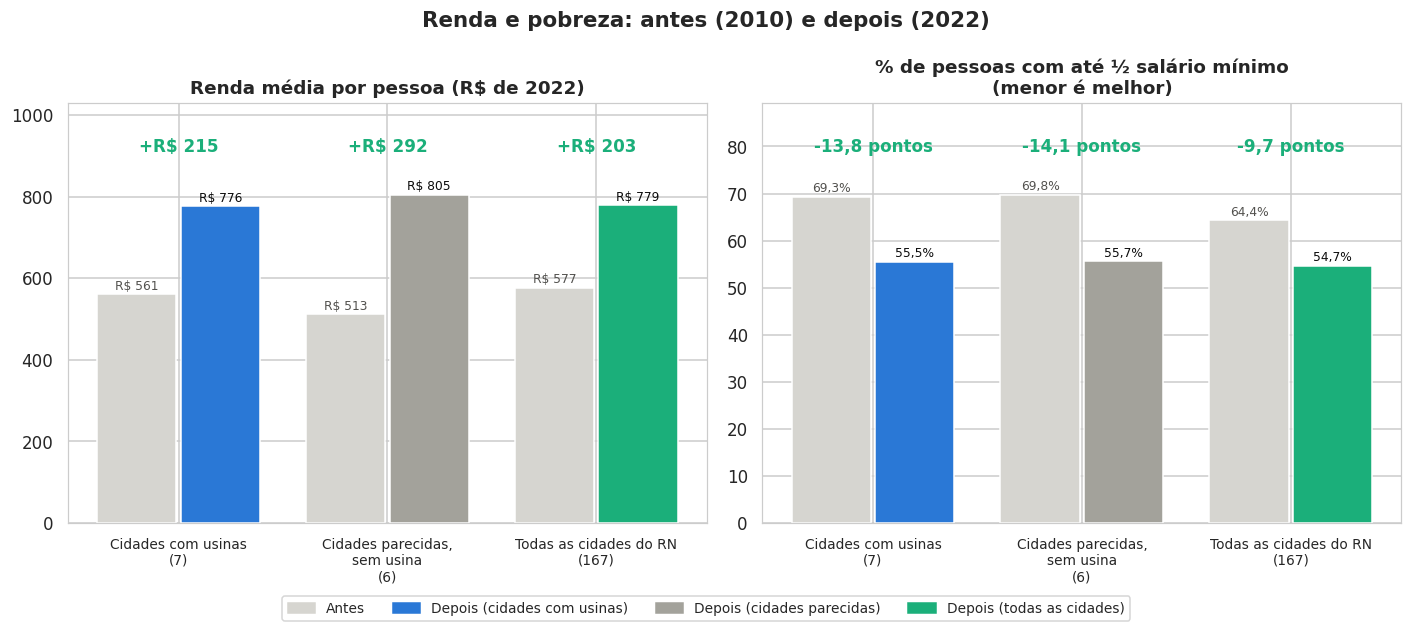

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
antes_depois(axes[0], 'renda10_preco22', 'renda22', 'Renda média por pessoa (R$ de 2022)', lambda v: reais(v))
antes_depois(axes[1], 'pobre10', 'pobre22', '% de pessoas com até ½ salário mínimo\n(menor é melhor)', pct,
             maior_e_melhor=False, formato_mudanca=pontos)
fig.suptitle('Renda e pobreza: antes (2010) e depois (2022)', fontweight='bold', fontsize=14)
legenda_antes_depois(fig)
plt.tight_layout()
plt.savefig('graficos/10_renda_pobreza.png', bbox_inches='tight')
plt.show()

**Leitura:** todos os grupos ficaram menos pobres e com mais renda. As cidades com usinas **não melhoraram mais**
que as parecidas: a renda subiu menos (+R$ 215 contra +R$ 292 por pessoa) e a pobreza caiu quase igual (13,8 contra
14,1 pontos).

### 5.2 Saneamento (Censo 2010 → 2022)

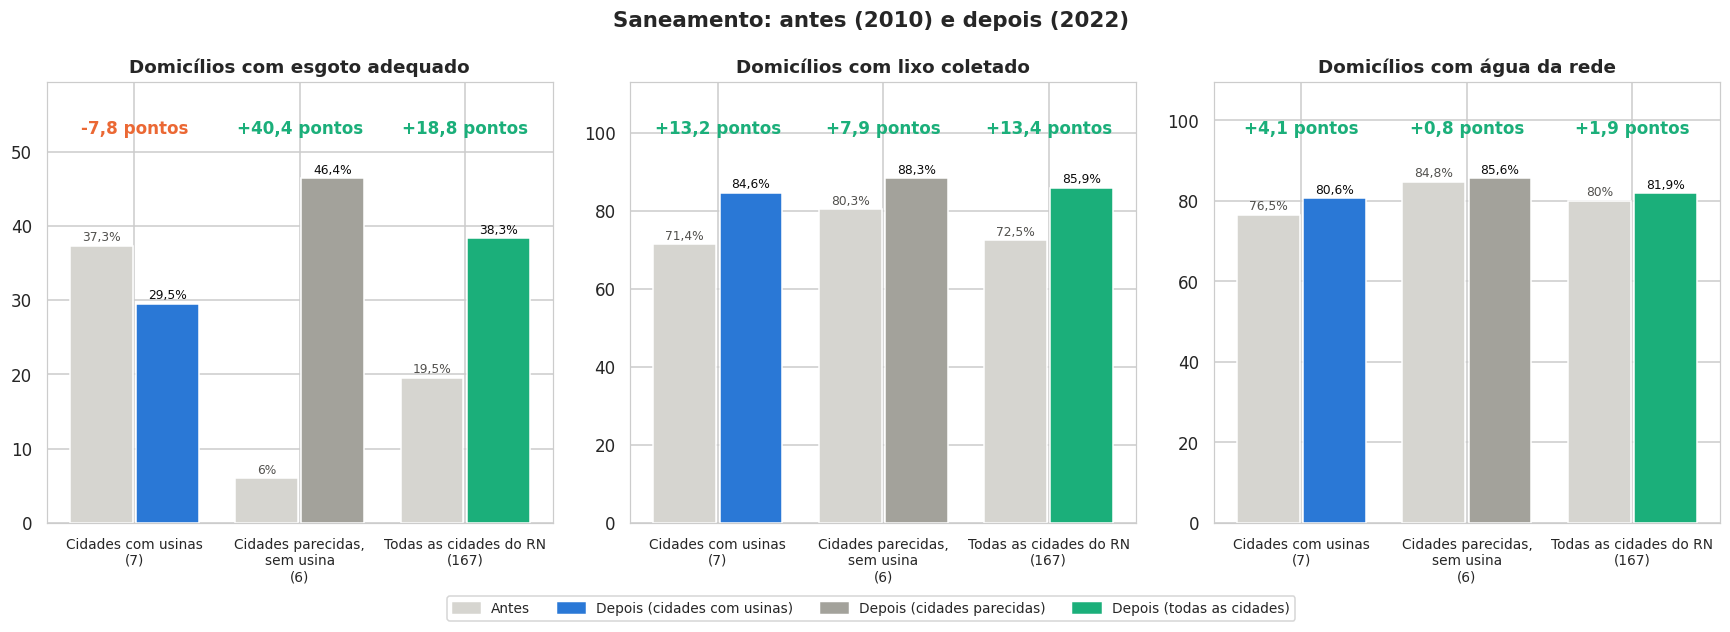

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
antes_depois(axes[0], 'esg10', 'esg22', 'Domicílios com esgoto adequado', pct, formato_mudanca=pontos)
antes_depois(axes[1], 'lixo10', 'lixo22', 'Domicílios com lixo coletado', pct, formato_mudanca=pontos)
antes_depois(axes[2], 'agua10', 'agua22', 'Domicílios com água da rede', pct, formato_mudanca=pontos)
fig.suptitle('Saneamento: antes (2010) e depois (2022)', fontweight='bold', fontsize=14)
legenda_antes_depois(fig)
plt.tight_layout()
plt.savefig('graficos/11_saneamento.png', bbox_inches='tight')
plt.show()

**Leitura:** as cidades com usinas **não se destacam**:
- **Lixo coletado:** melhoraram mais que as parecidas (+13,2 contra +7,9 pontos), mas igual à média do RN (+13,4).
- **Água da rede:** melhoraram um pouco mais (+4,1 contra +0,8 pontos), uma diferença pequena.
- **Esgoto:** pioraram (-7,8 pontos), enquanto as parecidas melhoraram muito (+40,4).

**Cuidado com o esgoto:** a pergunta do Censo sobre fossa mudou entre 2010 e 2022, e em cidades pequenas o número
oscila muito (Bodó caiu 30 pontos, São Bento do Norte 63). É o indicador menos confiável.

### 5.3 Educação: a nota das escolas da prefeitura (IDEB, 1º ao 5º ano)

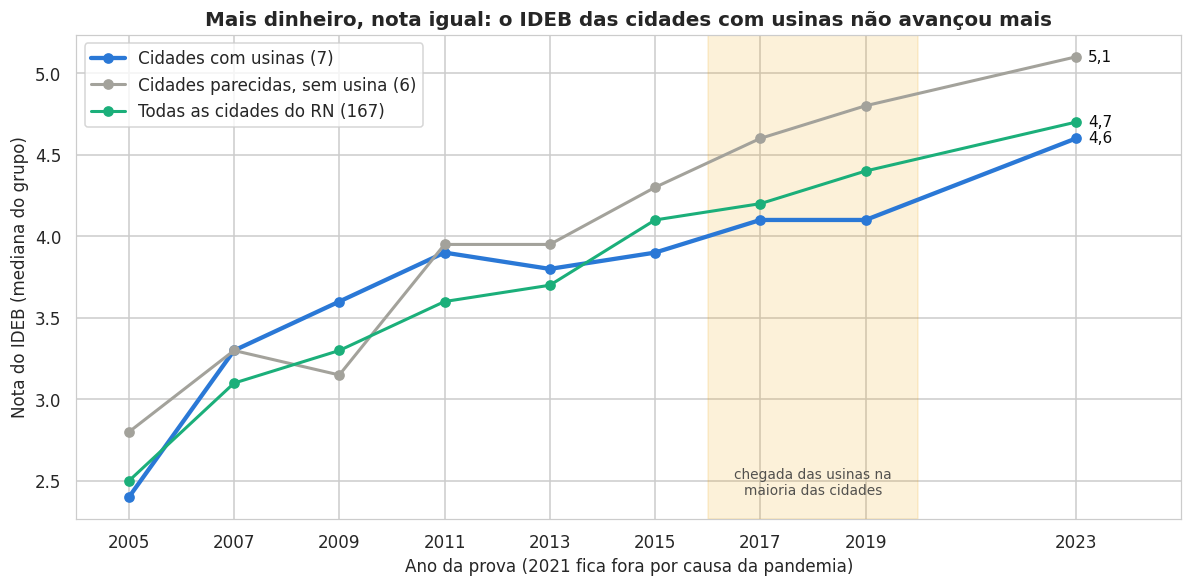

In [12]:
ANOS_IDEB = [2005, 2007, 2009, 2011, 2013, 2015, 2017, 2019, 2023]
evolucao = pd.DataFrame({g: info.loc[m, [f'ai_{a}' for a in ANOS_IDEB]].median().values for g, m in GRUPOS.items()},
                        index=ANOS_IDEB)

fig, ax = plt.subplots(figsize=(11, 5.5))
for coluna, cor in zip(evolucao.columns, CORES_GRUPO):
    ax.plot(evolucao.index, evolucao[coluna], marker='o', color=cor, linewidth=2.8 if cor == AZUL else 2, label=coluna)
    ax.annotate(virgula(evolucao[coluna].iloc[-1]), (evolucao.index[-1], evolucao[coluna].iloc[-1]), xytext=(8, 0),
                textcoords='offset points', va='center', color=TEXTO, fontsize=10)
ax.axvspan(2016, 2020, color=AMARELO, alpha=0.15)
ax.annotate('chegada das usinas na\nmaioria das cidades', (2018, evolucao.values.min()), ha='center', va='bottom',
            fontsize=9, color=TEXTO_2)
ax.set_xticks(ANOS_IDEB)
ax.set_xlim(2004, 2025)
ax.set_xlabel('Ano da prova (2021 fica fora por causa da pandemia)')
ax.set_ylabel('Nota do IDEB (mediana do grupo)')
ax.set_title('Mais dinheiro, nota igual: o IDEB das cidades com usinas não avançou mais')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('graficos/12_ideb_evolucao.png', bbox_inches='tight')
plt.show()

In [13]:
evolucao.round(2)

,Cidades com usinas (7),"Cidades parecidas, sem usina (6)",Todas as cidades do RN (167)
2005,2.4,2.8,2.5
2007,3.3,3.3,3.1
2009,3.6,3.1,3.3
2011,3.9,4.0,3.6
2013,3.8,4.0,3.7
2015,3.9,4.3,4.1
2017,4.1,4.6,4.2
2019,4.1,4.8,4.4
2023,4.6,5.1,4.7


**Leitura:**
- Até 2011, as escolas das cidades com usinas tinham nota **igual ou melhor** que as das outras cidades.
- Depois que as usinas chegaram, a nota delas **ficou abaixo** da das cidades parecidas e da mediana do RN.
- Isso acontece mesmo com essas prefeituras gastando cerca de **1,8 vez mais por habitante em educação**
  (notebook 06).

### 5.4 Saúde: mortalidade infantil (DATASUS)

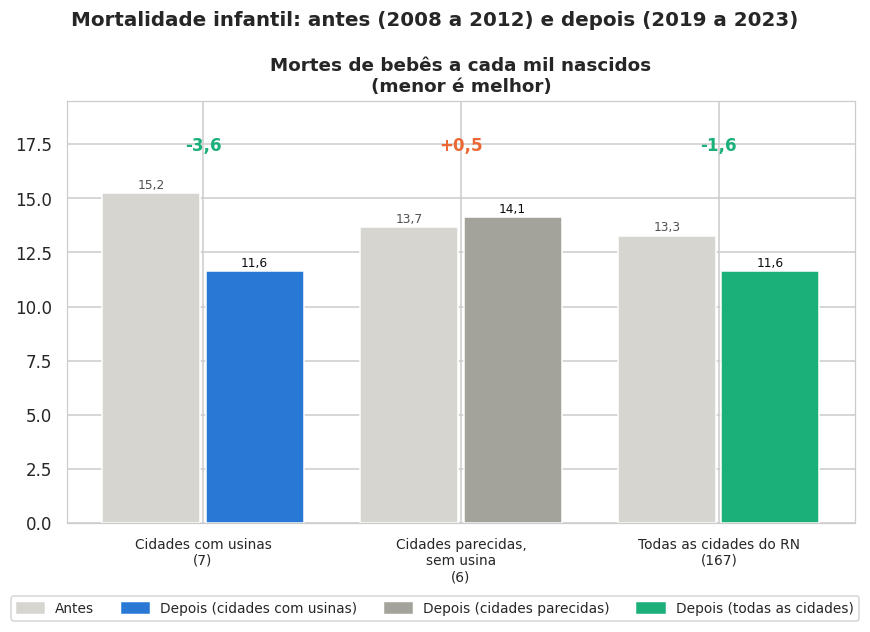

In [14]:
fig, ax = plt.subplots(figsize=(8, 5.5))
antes_depois(ax, 'mi_antes', 'mi_depois', 'Mortes de bebês a cada mil nascidos\n(menor é melhor)',
             lambda v: virgula(v, 1), maior_e_melhor=False)
fig.suptitle('Mortalidade infantil: antes (2008 a 2012) e depois (2019 a 2023)', fontweight='bold', fontsize=13)
legenda_antes_depois(fig)
plt.tight_layout()
plt.savefig('graficos/13_mortalidade_infantil.png', bbox_inches='tight')
plt.show()

**Leitura:** a mortalidade infantil caiu mais nas cidades com usinas. Mas são cidades muito pequenas: em Galinhos,
por exemplo, nascem cerca de 35 bebês por ano: somando os 5 anos, 1 morte a mais ou a menos muda a taxa em quase
6 pontos. É um
**sinal**, não uma prova (o teste da seção 7 não confirma).

## 6. Par a par: em quantos casos a cidade com usina melhorou mais?
Comparamos cada cidade com usina com a sua cidade parecida. Para cada indicador contamos em quantos dos 7 pares a
cidade com usina melhorou mais.

In [15]:
COMPARAR = {'renda_cresc': 'Renda', 'queda_pobreza': 'Queda da pobreza', 'mais_esgoto': 'Esgoto adequado',
            'mais_lixo': 'Lixo coletado', 'mais_agua': 'Água da rede', 'mais_ideb_ai': 'IDEB 1º ao 5º ano',
            'mais_ideb_af': 'IDEB 6º ao 9º ano', 'queda_mort_infantil': 'Queda da mortalidade infantil'}
vantagem = pd.DataFrame({p['com_usina']: info.loc[p['com_usina'], list(COMPARAR)] - info.loc[p['parecida'], list(COMPARAR)]
                         for _, p in PARES.iterrows()}).T.astype(float).rename(columns=COMPARAR).round(2)
placar = pd.DataFrame({'com usina melhorou mais': (vantagem > 0).sum(),
                       'parecida melhorou mais': (vantagem < 0).sum()})
placar['empate ou sem dado'] = len(vantagem) - placar.sum(axis=1)
placar = placar.sort_values('com usina melhorou mais')
print('Diferença de melhora em cada par (positivo = a cidade com usina melhorou mais):')
display(vantagem.round(1))
placar

Diferença de melhora em cada par (positivo = a cidade com usina melhorou mais):


,Renda,Queda da pobreza,Esgoto adequado,Lixo coletado,Água da rede,IDEB 1º ao 5º ano,IDEB 6º ao 9º ano,Queda da mortalidade infantil
Guamaré,-18.7,-7.2,15.5,-0.2,-48.5,-0.8,1.0,7.0
São Bento do Norte,-19.0,-1.5,-69.4,22.8,36.2,0.0,0.8,7.0
Pedra Grande,57.1,3.1,53.0,12.9,35.6,-0.1,1.0,10.2
Parazinho,-6.6,1.3,9.8,-1.8,-12.2,0.0,-1.0,-9.6
Galinhos,19.5,26.3,-47.0,-0.6,-29.2,-1.7,-0.3,0.8
Bodó,-16.0,3.3,-93.5,0.2,-19.8,-1.8,NaN,25.9
Serra do Mel,-12.8,-0.5,-12.6,47.6,6.2,-0.8,-1.8,2.2


,com usina melhorou mais,parecida melhorou mais,empate ou sem dado
IDEB 1º ao 5º ano,1,5,1
Renda,2,5,0
Água da rede,3,4,0
Esgoto adequado,3,4,0
IDEB 6º ao 9º ano,3,3,1
Queda da pobreza,4,3,0
Lixo coletado,4,3,0
Queda da mortalidade infantil,6,1,0


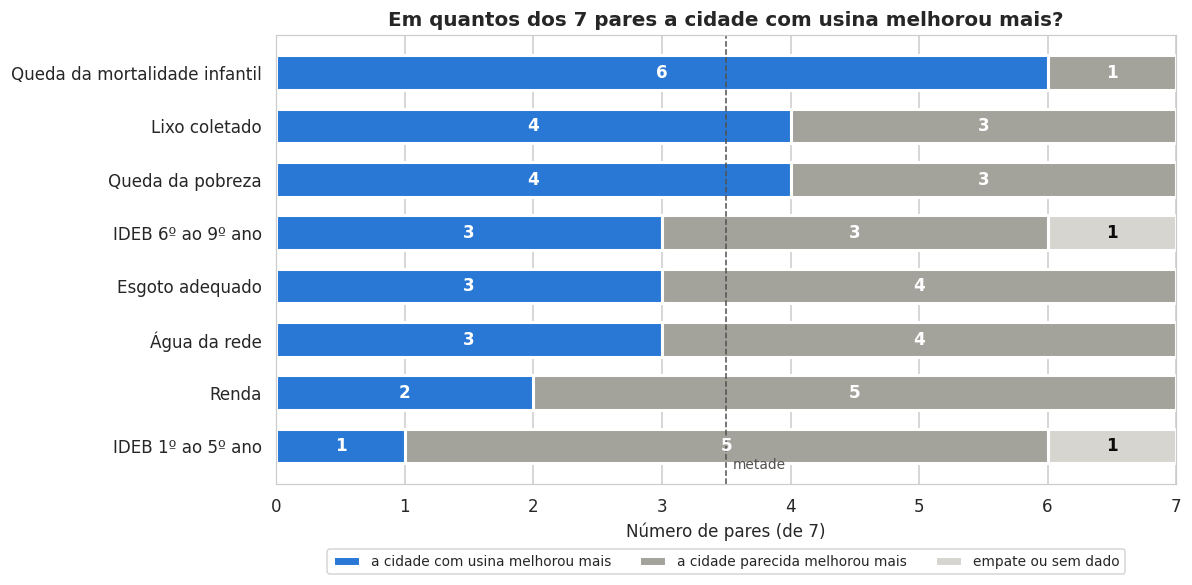

In [16]:
fig, ax = plt.subplots(figsize=(11, 5.5))
esquerda = np.zeros(len(placar))
for coluna, cor in zip(placar.columns, [AZUL, CINZA, CINZA_CLARO]):
    ax.barh(placar.index, placar[coluna], left=esquerda, color=cor, edgecolor='white', linewidth=2, height=0.65,
            label=coluna.replace('com usina', 'a cidade com usina').replace('parecida melhorou', 'a cidade parecida melhorou'))
    for i, v in enumerate(placar[coluna]):
        if v > 0:
            ax.annotate(str(v), (esquerda[i] + v / 2, i), ha='center', va='center', fontsize=11, fontweight='bold',
                        color='white' if cor != CINZA_CLARO else TEXTO)
    esquerda += placar[coluna].values
ax.axvline(3.5, color=TEXTO_2, linestyle='--', linewidth=1)
ax.annotate('metade', (3.55, -0.48), ha='left', va='bottom', fontsize=9, color=TEXTO_2)
ax.set_xlim(0, 7)
ax.set_xticks(range(8))
ax.set_xlabel('Número de pares (de 7)')
ax.set_title('Em quantos dos 7 pares a cidade com usina melhorou mais?')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9)
plt.tight_layout()
plt.savefig('graficos/14_placar_pares.png', bbox_inches='tight')
plt.show()

**Leitura:**
- **IDEB do 1º ao 5º ano:** a cidade com usina melhorou **menos** que a parecida em **5 dos 7 pares**. Só Parazinho
  melhorou mais, por 0,05 ponto, e São Bento do Norte empatou.
- **Mortalidade infantil:** a cidade com usina melhorou mais em 6 dos 7 pares, mas com o cuidado da seção 5.4
  (números muito pequenos).
- **Renda, pobreza e saneamento:** perto da metade; nenhum lado se destaca.

## 7. Conferindo com todas as 167 cidades

Os pares são só 7. Para ter mais segurança, olhamos as **167 cidades** e perguntamos: **as cidades cujo repasse
cresceu mais melhoraram mais?** Usamos uma regressão que compara cidades que estavam **no mesmo ponto em 2010** e
têm o **mesmo tamanho** (cidades piores em 2010 tendem a melhorar mais, e isso precisa ser descontado).

A coluna "chance de ser acaso" é o p-valor: abaixo de 5%, consideramos que a relação é real.

In [17]:
def regressao(y, controles, dados):
    """Mínimos quadrados com erro-padrão robusto (HC1). Devolve o efeito de log(vezes_rep) e o p-valor."""
    t = dados[[y, 'log_vezes_rep'] + controles].dropna()
    X = np.column_stack([np.ones(len(t))] + [t[c] for c in ['log_vezes_rep'] + controles])
    Y = t[y].values
    b = np.linalg.lstsq(X, Y, rcond=None)[0]
    e = Y - X @ b
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    V = XtX_inv @ (X.T * e ** 2) @ X @ XtX_inv * n / (n - k)
    p = 2 * (1 - stats.t.cdf(abs(b[1] / np.sqrt(V[1, 1])), n - k))
    return b[1], p, n

d['log_vezes_rep'] = np.log(d['vezes_rep'])
d['log_renda10'] = np.log(d['renda10'])
TESTES = [  # (coluna da melhora, ponto de partida, nome, unidade)
    ('renda_cresc', 'log_renda10', 'Renda', '% a mais de crescimento'),
    ('queda_pobreza', 'pobre10', 'Queda da pobreza', 'pontos percentuais a mais'),
    ('mais_esgoto', 'esg10', 'Esgoto adequado', 'pontos percentuais'),
    ('mais_lixo', 'lixo10', 'Lixo coletado', 'pontos percentuais'),
    ('mais_agua', 'agua10', 'Água da rede', 'pontos percentuais'),
    ('mais_ideb_ai', 'ai_antes', 'IDEB 1º ao 5º ano', 'pontos de nota'),
    ('mais_ideb_af', 'af_antes', 'IDEB 6º ao 9º ano', 'pontos de nota'),
    ('queda_mort_infantil', 'mi_antes', 'Queda da mortalidade infantil', 'mortes a menos por mil'),
]
linhas = []
for coluna, partida, nome, unidade in TESTES:
    efeito, p, n = regressao(coluna, [partida, 'log_pop'], d)
    resposta = ('sim, um pouco' if efeito > 0 else 'não (melhorou menos)') if p < 0.05 else 'não'
    linhas.append({'área': nome, 'cidades com dado': n,
                   'quem teve o repasse dobrado melhorou a mais': f'{virgula(efeito * np.log(2), 2)} {unidade}',
                   'chance de ser acaso': f'{p:.0%}',
                   'quem ganhou mais repasse melhorou mais?': resposta})
pd.DataFrame(linhas).set_index('área')

,cidades com dado,quem teve o repasse dobrado melhorou a mais,chance de ser acaso,quem ganhou mais repasse melhorou mais?
área,,,,
Renda,167,"3,97 % a mais de crescimento",9%,não
Queda da pobreza,167,"1,48 pontos percentuais a mais",2%,"sim, um pouco"
Esgoto adequado,167,"-0,75 pontos percentuais",85%,não
Lixo coletado,167,"-0,10 pontos percentuais",93%,não
Água da rede,167,"1,53 pontos percentuais",25%,não
IDEB 1º ao 5º ano,162,"0,02 pontos de nota",68%,não
IDEB 6º ao 9º ano,145,"0,02 pontos de nota",80%,não
Queda da mortalidade infantil,167,"0,30 mortes a menos por mil",60%,não


**Leitura:**
- **Educação, saneamento e saúde: não.** Com as 167 cidades, ganhar mais repasse **não** está ligado a melhorar
  mais nessas áreas. É o mesmo que os pares mostraram.
- **Pobreza: sim, um pouco.** As cidades com o repasse dobrado tiveram cerca de 1,5 ponto percentual a mais de queda
  da pobreza em 12 anos. Mas não dá para saber se isso vem da **prefeitura** ou da **própria usina** (emprego na
  obra e aluguel pago aos donos das terras onde ficam as torres eólicas). O repasse e a usina chegam juntos.

## 8. Conclusões

**A pergunta:** o dinheiro a mais que as cidades com usinas recebem virou melhoria para a população?

**1. Na educação, não.** É o resultado mais firme. Antes das usinas, as escolas dessas cidades tinham nota igual ou
melhor que as outras; depois, ficaram abaixo, mesmo com a prefeitura gastando quase o dobro por habitante em
educação. Nos pares, a cidade com usina melhorou menos em 5 de 7 casos, e o teste com as 167 cidades não mostra
nenhuma relação.

**2. No saneamento, não.** Esgoto, coleta de lixo e água melhoraram no mesmo ritmo nas cidades com e sem usina.

**3. Na saúde, não dá para afirmar.** A mortalidade infantil caiu mais nas cidades com usinas, mas os números são
pequenos demais e o teste com as 167 cidades não confirma.

**4. Na renda e na pobreza, um efeito pequeno, que pode ser da usina e não da prefeitura.**

**Frase-resumo:** o repasse a mais fica na prefeitura e **não encontramos sinais de que tenha virado melhores
serviços** (escola, saneamento, saúde) para a população, pelo menos até 2022–2023.

**Cuidados (para dizer na apresentação):**
- São só 7 cidades com usinas: os pares mostram tendências; o teste com as 167 cidades é o mais confiável.
- O dinheiro grande chegou entre 2016 e 2020 na maioria delas. Escola e saneamento levam tempo para mudar, e pode
  ser cedo para ver o efeito.
- Algumas perguntas do Censo mudaram entre 2010 e 2022 (esgoto, principalmente).
- Estamos dizendo que a melhora **não aparece** nos dados, não que o dinheiro foi desviado ou mal gasto.